In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pennylane as qml

In [2]:
# Stany bazowe i bramka Hadamarda

ket0 = np.array([1, 0], dtype=complex)  # |0⟩
ket1 = np.array([0, 1], dtype=complex)  # |1⟩

H = np.array([[1,  1], 
              [1, -1]], dtype=complex) / np.sqrt(2)

In [3]:
# Superpozycja i pomiary

plus = H @ ket0

print("stan:", np.round(plus, 3))
print("P(0), P(1):", np.round(np.abs(plus)**2, 3))

stan: [0.707+0.j 0.707+0.j]
P(0), P(1): [0.5 0.5]


In [4]:
# Dwa kubity i splątanie

ket00 = np.kron(ket0, ket0)   # |00⟩ = |0⟩ ⊗ |0⟩

I = np.eye(2, dtype=complex)

CNOT = np.array([[1, 0, 0, 0],
                 [0, 1, 0, 0],
                 [0, 0, 0, 1],
                 [0, 0, 1, 0]], dtype=complex)

bell = CNOT @ np.kron(H, I) @ ket00   # najpierw H na kubicie 0, potem CNOT

print("stan:", np.round(bell, 3))
print("P(00), P(01), P(10), P(11):", np.round(np.abs(bell)**2, 3))

stan: [0.707+0.j 0.   +0.j 0.   +0.j 0.707+0.j]
P(00), P(01), P(10), P(11): [0.5 0.  0.  0.5]


In [5]:
# Shoty, czyli jak to wygląda w praktyce

rng = np.random.default_rng(42)
probs = np.abs(bell)**2
wyniki = rng.choice(["00", "01", "10", "11"], size=1000, p=probs)
etykiety, liczby = np.unique(wyniki, return_counts=True)
print(dict(zip(etykiety, liczby)))

{np.str_('00'): np.int64(503), np.str_('11'): np.int64(497)}


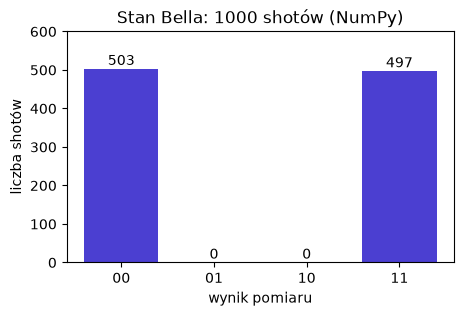

In [6]:
wszystkie = ["00", "01", "10", "11"]
zliczenia = {w: int(np.sum(wyniki == w)) for w in wszystkie}

plt.figure(figsize=(5, 3))
plt.bar(zliczenia.keys(), zliczenia.values(), color="#4b3fd1")
plt.xlabel("wynik pomiaru")
plt.ylabel("liczba shotów")
plt.title("Stan Bella: 1000 shotów (NumPy)")
for w, n in zliczenia.items():
    plt.text(w, n + 10, n, ha="center")
plt.ylim(0, 600)
plt.show()